# Business Insights

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Sample retail transactions (illustrative data)
df = pd.DataFrame({
    "Month": ["Jan","Jan","Jan","Feb","Feb","Feb","Mar","Mar","Mar","Apr","Apr","Apr"],
    "Category": ["Electronics","Clothing","Home"] * 4,
    "Orders": [40,70,55,45,72,58,55,75,60,65,80,62],
    "Sales": [120000,70000,44000,135000,72000,46400,165000,75000,48000,195000,80000,49600],
    "Returns": [2,3,4,2,4,5,3,4,6,3,5,8],
    "Region": ["South","North","West"] * 4
})
df["Return_Rate"] = df["Returns"] / df["Orders"] * 100
print(df.head())

  Month     Category  Orders   Sales  Returns Region  Return_Rate
0   Jan  Electronics      40  120000        2  South     5.000000
1   Jan     Clothing      70   70000        3  North     4.285714
2   Jan         Home      55   44000        4   West     7.272727
3   Feb  Electronics      45  135000        2  South     4.444444
4   Feb     Clothing      72   72000        4  North     5.555556


# 1. Important Patterns
# Definition
A pattern is a repeated or consistent characteristic visible in data. It may appear in sales, purchasing behavior, returns, or customer activity. Patterns help us understand what usually happens in a business. They should be supported by comparisons rather than guesses.

# Business Example
A retail manager notices that Electronics consistently generates more revenue than other categories. The manager compares monthly revenue to check whether this result repeats. This can guide inventory and promotion planning. The manager should also check profitability before increasing investment.

# AI/ML Use
During EDA, repeated patterns can suggest useful predictive features. For example, product category may help explain sales differences. A model can learn such patterns when training data is representative. The relationship should still be checked on new data.

# Python Example

Category
Electronics    615000
Clothing       297000
Home           188000
Name: Sales, dtype: int64


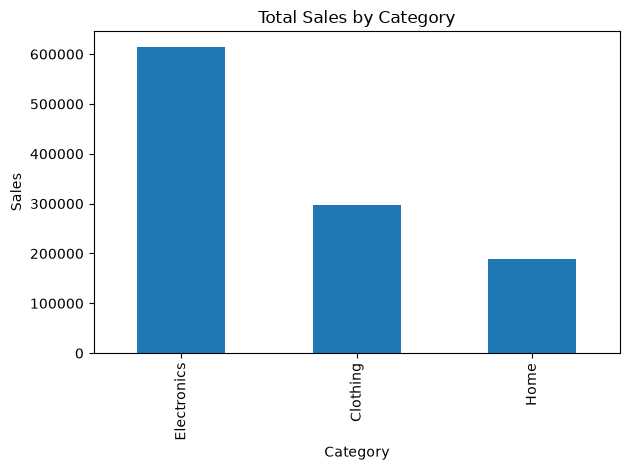

In [2]:
sales_by_category = df.groupby("Category")["Sales"].sum().sort_values(ascending=False)
print(sales_by_category)
sales_by_category.plot(kind="bar", title="Total Sales by Category")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()

# Explanation
Electronics has the highest total sales in this sample. This is an observation based on category totals, not proof of the highest profit. A possible business insight is to review Electronics stock availability. Compare margins and costs before deciding.

# 2. Trends
# Definition
A trend is a general direction of change over time. Values may increase, decrease, or remain approximately stable. Trends are easier to identify when dates are ordered correctly. A short-term movement does not always represent a long-term trend.

# Business Example
A shop compares revenue from January to April to see whether business is growing. If sales rise steadily, it may plan for additional stock. If sales fall, the team can investigate pricing or demand. More months would be needed to check seasonality.

# AI/ML Use
Time-based trends can support forecasting and demand prediction. Month or lagged sales may be useful features in a model. Training and evaluation must preserve time order. Future information should not leak into earlier predictions.

# Python Example

Month
Jan    234000
Feb    253400
Mar    288000
Apr    324600
Name: Sales, dtype: int64


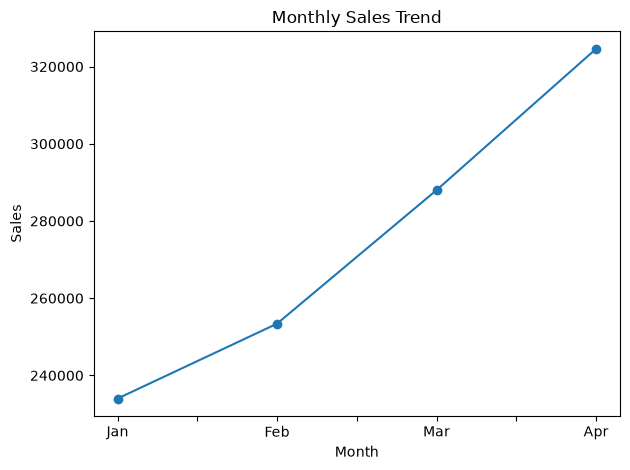

In [3]:
monthly_sales = df.groupby("Month", sort=False)["Sales"].sum()
print(monthly_sales)
monthly_sales.plot(marker="o", title="Monthly Sales Trend")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()

# Explanation
Total sales increase from January through April in the sample. The observation suggests rising revenue during these four months. A business opportunity is to plan inventory for continuing demand. Four months alone are not enough to confirm a long-term growth trend.

# 3. Relationships
# Definition
A relationship describes how two variables change or differ together. For example, orders and revenue may rise together. A relationship can be positive, negative, or unclear. Correlation or a visual association does not establish causation.

# Business Example
A store compares order counts with sales revenue across product categories. More orders may lead to more sales, but product prices also matter. Electronics may earn more revenue with fewer orders. This helps teams separate volume from transaction value.

# AI/ML Use
Relationships help identify candidate features for predictive models. Order volume may be useful for estimating revenue. Analysts should consider price and product category as additional variables. They should avoid treating correlation as proof of cause.

# Python Example

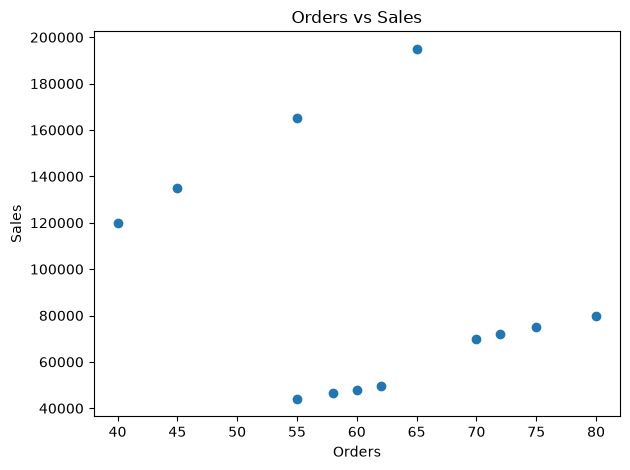

Correlation: -0.27


In [4]:
plt.scatter(df["Orders"], df["Sales"])
plt.xlabel("Orders")
plt.ylabel("Sales")
plt.title("Orders vs Sales")
plt.tight_layout()
plt.show()
print("Correlation:", round(df["Orders"].corr(df["Sales"]), 2))

# Explanation
In this sample, sales and orders do not have a simple positive relationship across all categories. Electronics produces high revenue with comparatively fewer orders. The insight is that average order value differs by category. Pricing and product mix should be examined before making volume-based decisions.

# 4. Anomalies
# Definition
An anomaly is an observation that differs from the usual pattern. It may be a genuine event, a rare business situation, or an error. Anomalies can appear in sales, return rates, or transaction amounts. They should be investigated before being removed or corrected.

# Business Example
A retail team notices an unusually high return rate for Home products in April. The issue could be related to quality, shipping, or incorrect records. The team checks return reasons and transaction logs. This avoids making decisions from an unexplained spike.

# AI/ML Use
Anomalies may distort model training and evaluation. They can also signal fraud, operational faults, or rare but valid behavior. Analysts should verify suspicious records with domain context. Do not automatically delete all unusual values.

# Python Example

Month  Orders  Returns  Return_Rate
  Jan      55        4     7.272727
  Feb      58        5     8.620690
  Mar      60        6    10.000000
  Apr      62        8    12.903226


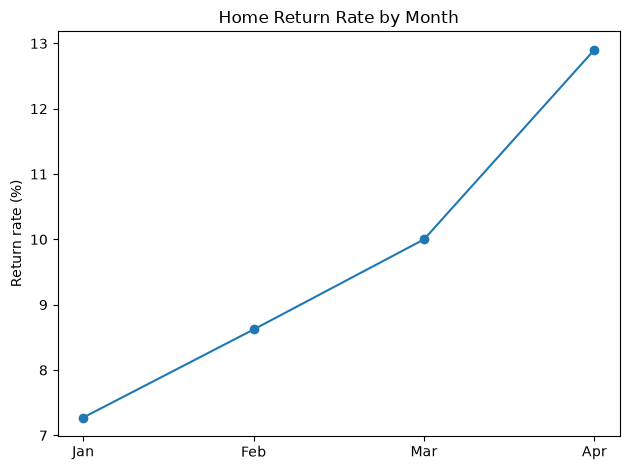

In [5]:
home = df[df["Category"] == "Home"][ ["Month", "Orders", "Returns", "Return_Rate"] ]
print(home.to_string(index=False))
plt.plot(home["Month"], home["Return_Rate"], marker="o")
plt.title("Home Return Rate by Month")
plt.ylabel("Return rate (%)")
plt.tight_layout()
plt.show()

# Explanation
Home return rates rise across the four months, with the highest rate in April. This is a warning signal, not confirmed evidence of defective products. The business should inspect reasons for returns and verify the records. The observation should be retained until its cause is understood.

# 5. Potential Business Problems
# Definition
A potential business problem is a measurable issue that may reduce revenue, efficiency, or customer satisfaction. EDA can reveal warning signs, but it cannot always explain their causes. A good problem statement names the affected metric and group. It also suggests what should be checked next.

# Business Example
A company sees increasing returns in its Home category. Returns may create shipping and replacement costs. The operations team can review packaging, suppliers, and customer feedback. The goal is to identify the cause before applying a solution.

# AI/ML Use
Business problems can become ML tasks such as predicting returns or identifying risky orders. The target variable must be clearly defined. Features must be available before the event being predicted. Model performance should be measured using business-relevant metrics.

# Python Example

In [6]:

category_returns = df.groupby("Category").agg(Orders=("Orders", "sum"), Returns=("Returns", "sum"))
category_returns["Return_Rate"] = 100 * category_returns["Returns"] / category_returns["Orders"]
print(category_returns.round(2))

             Orders  Returns  Return_Rate
Category                                 
Clothing        297       16         5.39
Electronics     205       10         4.88
Home            235       23         9.79


# Explanation
Home has the highest overall return rate in this sample. This identifies a possible operational problem worth investigating. A useful next step is to compare product defects, delivery damage, and return reasons. The data alone cannot identify which cause is responsible.

# 6. Interesting Segments
# Definition
A segment is a group of records sharing a meaningful characteristic. Segments can be defined by product category, region, customer type, or behavior. Comparing segments helps reveal differences hidden in overall averages. Small groups should be interpreted carefully.

# Business Example
A retailer separates transactions by category to understand how different products perform. Electronics brings high revenue, while Clothing generates many orders. Each segment may need a different strategy. Managers should compare sales, orders, and margins together.

# AI/ML Use
Segments can improve feature engineering and subgroup evaluation. Category labels may help a model represent different purchasing behavior. Performance should also be checked across important groups. This helps identify where a model works poorly.

# Python Example

In [7]:
segments = df.groupby("Category").agg(Total_Sales=("Sales", "sum"), Total_Orders=("Orders", "sum"))
segments["Sales_per_Order"] = segments["Total_Sales"] / segments["Total_Orders"]
print(segments.round(2))

             Total_Sales  Total_Orders  Sales_per_Order
Category                                               
Clothing          297000           297           1000.0
Electronics       615000           205           3000.0
Home              188000           235            800.0


# Explanation
Electronics has the highest sales per order, while Clothing has the most orders. These segments behave differently in the sample. Electronics may benefit from premium-product planning, while Clothing may need volume-focused operations. Profitability and customer demand should be verified first.

# 7. Potential Opportunities
# Definition
A potential opportunity is an area where the business might improve revenue, cost, or customer experience. EDA can suggest opportunities by showing unmet demand or performance differences. An opportunity is a hypothesis rather than a guaranteed outcome. It should be tested with business constraints and additional evidence.

# Business Example
A retailer notices that Electronics revenue is rising month by month. It may consider improving stock availability for popular products. At the same time, Home returns may indicate an opportunity to improve quality control. Both actions need cost and feasibility checks.

# AI/ML Use
Insights can guide ML projects such as sales forecasting or return-risk prediction. Forecasts may help plan inventory. Return models may help prioritize quality checks. Any proposed model should be evaluated against a simple baseline and business costs.

# Python Example

Category  Clothing  Electronics   Home
Month                                 
Jan          70000       120000  44000
Feb          72000       135000  46400
Mar          75000       165000  48000
Apr          80000       195000  49600


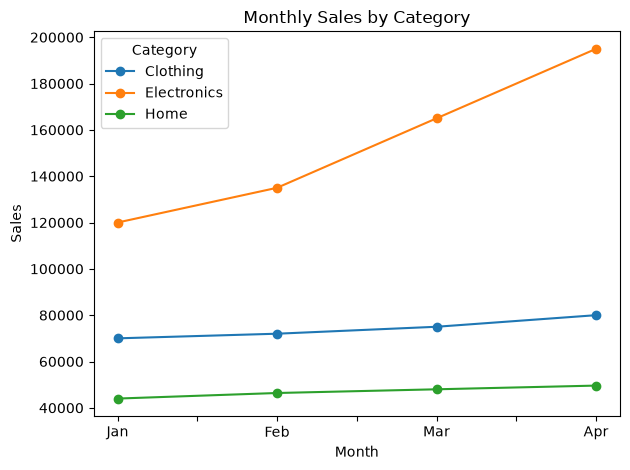

In [8]:
category_month = df.pivot(index="Month", columns="Category", values="Sales")
category_month = category_month.loc[["Jan", "Feb", "Mar", "Apr"]]
print(category_month)
category_month.plot(marker="o", title="Monthly Sales by Category")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()

# Explanation
Electronics revenue grows from January to April, suggesting a possible inventory-planning opportunity. Home revenue grows more slowly and has increasing return rates. These are two different business priorities. The next step is to test proposed actions using profit, stock, and customer feedback data.